# eda


In [1]:
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
if not (root / "data" / "raw" / "train.json").exists():
    root = root.parent
raw = root / "data" / "raw"
names = [line.strip() for line in (raw / "classes.txt").read_text().splitlines() if line.strip()]
print(names)

def load(split):
    return json.loads((raw / f"{split}.json").read_text())

for split in ("train", "valid", "test"):
    data = load(split)
    print(split, len(data["images"]), "картинок", len(data["annotations"]), "боксов", data["images"][0]["width"], "px")


['aircraft', 'ship', 'vehicle']
train 2094 картинок 43468 боксов 640 px
valid 449 картинок 8362 боксов 640 px
test 449 картинок 11751 боксов 640 px


{'aircraft': 10596, 'ship': 1771, 'vehicle': 39463}
объектов на кадр 20.381439244986236 max 1091


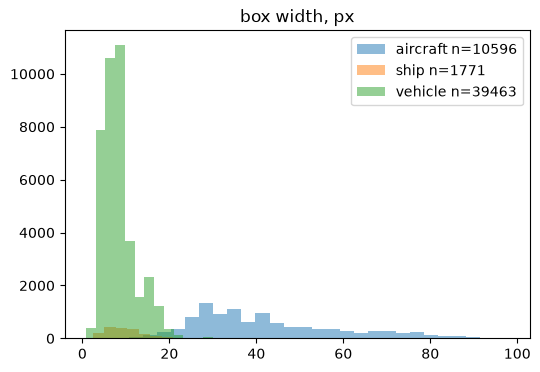

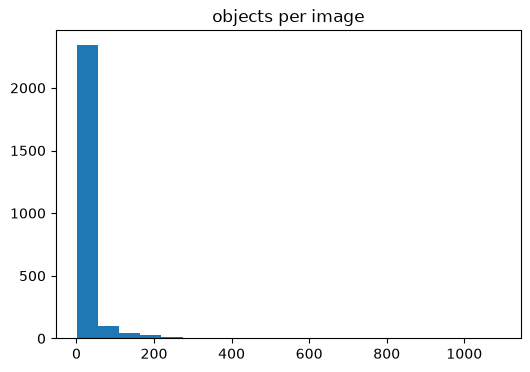

In [2]:
out = root / "eda_out"
out.mkdir(exist_ok=True)

box_w = {i: [] for i in range(len(names))}
class_n = {i: 0 for i in range(len(names))}
per_image = []
# test не читаю
for split in ("train", "valid"):
    data = load(split)
    by_image = {}
    for ann in data["annotations"]:
        by_image.setdefault(ann["image_id"], []).append(ann)
    for image in data["images"]:
        anns = by_image.get(image["id"], [])
        per_image.append(len(anns))
        for ann in anns:
            c = ann["category_id"] - 1
            class_n[c] += 1
            box_w[c].append(ann["bbox"][2])

print({names[i]: class_n[i] for i in class_n})
print("объектов на кадр", float(np.mean(per_image)), "max", max(per_image))

fig, ax = plt.subplots(figsize=(6, 4))
for i, name in enumerate(names):
    ax.hist(box_w[i], bins=30, alpha=0.5, label=f"{name} n={class_n[i]}")
ax.set_title("box width, px")
ax.legend()
fig.savefig(out / "box_width.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(per_image, bins=20)
ax.set_title("objects per image")
fig.savefig(out / "per_image.png", bbox_inches="tight")
plt.show()


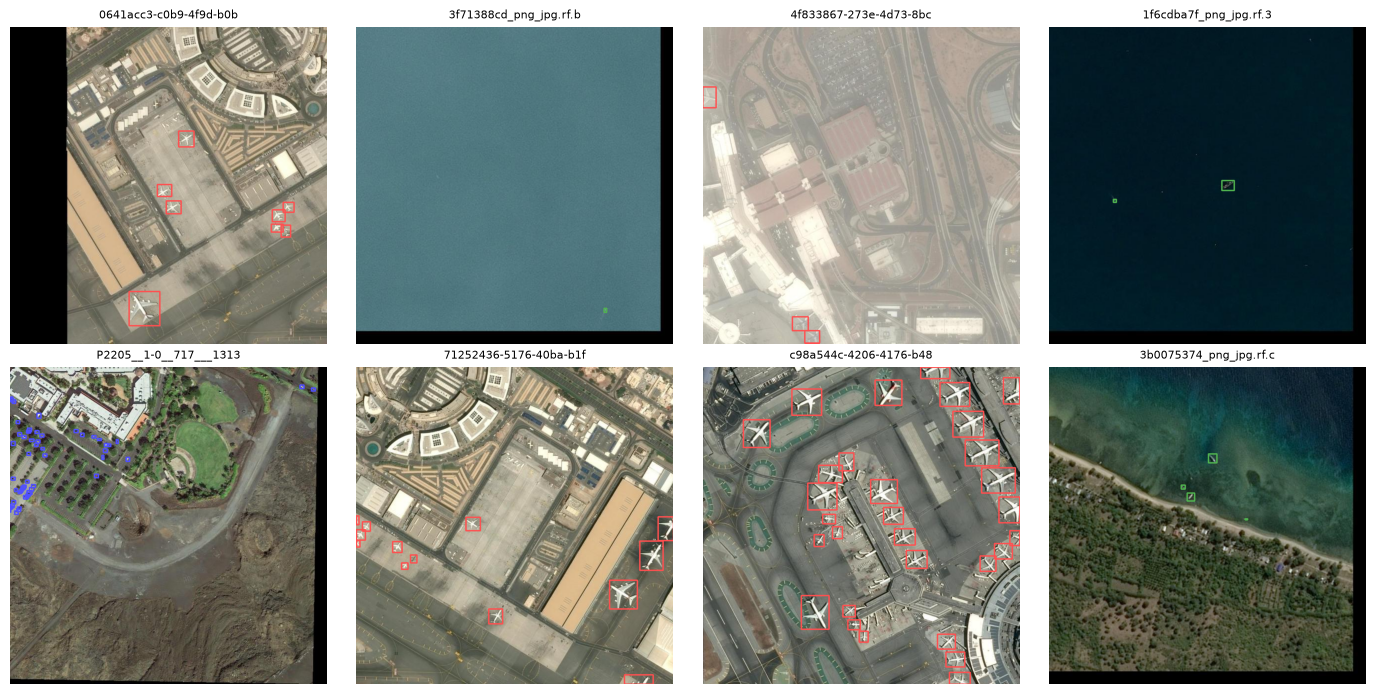

In [3]:
import random
from collections import defaultdict

random.seed(0)
data = load("train")
by_image = defaultdict(list)
for ann in data["annotations"]:
    by_image[ann["image_id"]].append(ann)
sample = random.sample(data["images"], 8)
colors = [(255, 80, 80), (80, 180, 80), (80, 80, 255)]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, image in zip(axes.ravel(), sample):
    bgr = cv2.imread(str(raw / "train" / image["file_name"]))
    im = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    for ann in by_image[image["id"]]:
        x, y, w, h = ann["bbox"]
        c = ann["category_id"] - 1
        cv2.rectangle(im, (int(x), int(y)), (int(x + w), int(y + h)), colors[c], 2)
    ax.imshow(im)
    ax.set_title(image["file_name"][:22], fontsize=8)
    ax.axis("off")
fig.tight_layout()
fig.savefig(out / "examples.png", bbox_inches="tight")
plt.show()
